# 11 Concept drift
Four drifts are built into the world: **sudden** (day 100: structuring into smaller payments), **gradual** (shrinking scam share-of-balance), **recurring** (campaign windows days 20-35 and 90-105), **feature** (fraud moves desktop to mobile, days 50-110).

In [1]:
import sys, pathlib, json, warnings; warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
def table(name):
    p = ROOT / 'reports' / 'tables' / name
    return pd.read_csv(p) if p.exists() else None

In [2]:
from presage.drift.detectors import run_detector, psi
rng = np.random.default_rng(0); stream = np.concatenate([(rng.random(1500)<.1),(rng.random(1500)<.6)]).astype(float)
for d in ['adwin','ddm','eddm','page_hinkley','kswin']: print(d, [round(a) for a in run_detector(d, stream, np.arange(3000.))][:3])

adwin [1535]
ddm [1509]
eddm [289, 674, 1011]
page_hinkley [1507, 2463]


kswin [1550]


### Detector benchmark on the real experiment (miss stream of a static model; alarms are raised when labels confirm)

In [3]:
d = table('drift_detectors.csv'); d[d.weekly_values.isna()].drop(columns='weekly_values') if d is not None else 'run scripts/run_drift.py --part detect'

,detector,n_alarms,false_alarms_before_drift,first_alarm_after_drift_day,detection_delay_days,first_alarm_day,mean_pre_drift,mean_post_drift
0,adwin,0,0,NaN,NaN,NaN,NaN,NaN
1,ddm,5,2,108.516897,8.516897,91.481726,NaN,NaN
2,eddm,0,0,NaN,NaN,NaN,NaN,NaN
3,page_hinkley,0,0,NaN,NaN,NaN,NaN,NaN
4,kswin,0,0,NaN,NaN,NaN,NaN,NaN


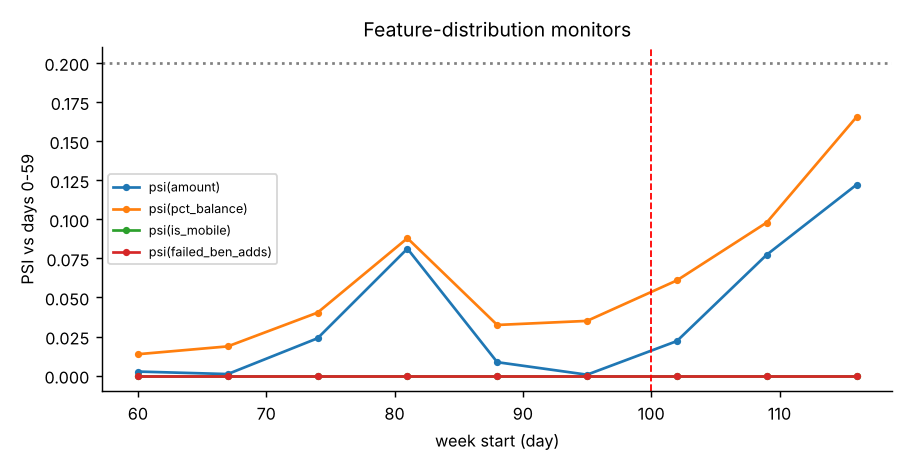

In [4]:
from IPython.display import Image, display
p = ROOT/'reports'/'figures'/'fig_drift_monitors.png'; display(Image(str(p))) if p.exists() else print('run make_figures.py')

### Adaptation strategies (walk-forward, weekly blocks from day 60, 3-day label delay)

In [5]:
s = table('drift_adaptation.csv'); s.round(3) if s is not None else 'run scripts/run_drift.py --part adapt'

,strategy,mean_pr_auc,pre_drift_pr_auc,post_drift_pr_auc,recall_at_1pct_fpr,n_retrains,retrain_seconds,probe_pr_auc_final,first_alarm_day,n_alarms
0,static,0.964,0.967,0.958,0.997,0,0.000,1.000,NaN,0
1,scheduled_14d,0.976,0.973,0.983,1.000,4,21.326,1.000,NaN,0
2,sliding_30d,0.983,0.979,0.989,1.000,8,14.147,0.820,NaN,0
3,drift_triggered_adwin,0.970,0.978,0.954,0.996,0,0.000,0.996,NaN,0
4,drift_triggered_ddm,0.970,0.978,0.954,0.996,0,0.000,0.996,NaN,0
5,incremental,0.966,0.964,0.972,0.993,8,2.400,0.991,NaN,0
6,replay_buffer,0.982,0.979,0.988,1.000,8,13.261,0.987,NaN,0


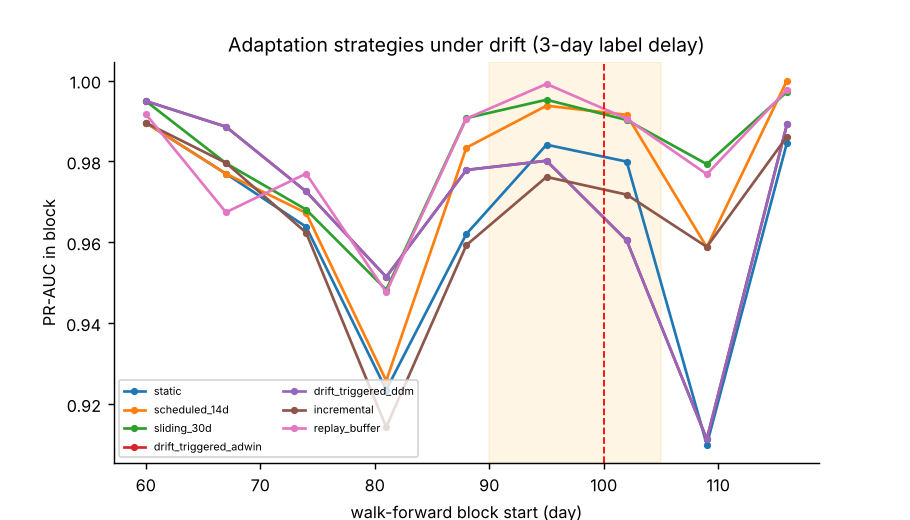

In [6]:
p = ROOT/'reports'/'figures'/'fig_drift_curves.png'; display(Image(str(p))) if p.exists() else None

Metrics: mean/pre/post-drift PR-AUC, recall at 1% FPR, retrains and compute seconds, first alarm day (adaptation delay >= label delay), and `probe_pr_auc_final` (final model scored on an early-period probe; a drop relative to `static` indicates forgetting).